In [ ]:
import os
import glob
import pandas as pd

def process_csv_groups(folder_path):
    groups = {}

    for subfolder in sorted(os.listdir(folder_path)):
        subfolder_path = os.path.join(folder_path, subfolder)
        if not os.path.isdir(subfolder_path):
            continue

        #determine which dataset group this subfolder belongs to
        group_key = None
        for i in range(15, 0, -1):
            tag = f"dataset{i}"
            if tag in subfolder:
                group_key = tag
                break

        if group_key is None:
            continue

        if group_key not in groups:
            groups[group_key] = {"names": set(), "files": []}

        #read blast_score_filter.txt in each subfolder
        csv_file = os.path.join(subfolder_path, "blast_score_filter.txt")
        if not os.path.isfile(csv_file) or os.path.getsize(csv_file) == 0:
            continue

        try:
            df = pd.read_csv(csv_file)
        except pd.errors.EmptyDataError:
            continue
        col = df.iloc[:, 1].dropna().astype(str).str.strip()
        groups[group_key]["names"].update(col[col != ""].unique())

        groups[group_key]["files"].append(os.path.join(subfolder, "blast_score_filter.txt"))

    #output results for each group
    for group_key in sorted(groups):
        info = groups[group_key]
        unique_names = sorted(info["names"])
        print(f"=== {group_key} ===")
        print(f"Source files: {', '.join(info['files'])}")
        print(f"Unique name count: {len(unique_names)}")
        print(f"Unique names: {unique_names}")
        print()
    return groups

In [2]:
folder = os.path.dirname("smallbarna_blastn_results/")
process_csv_groups(folder)

=== dataset1 ===
Source files: map_genome_srna_compare_dataset1_SRR18745680_final_form/blast_score_filter.txt, map_genome_srna_compare_dataset1_SRR18745681_final_form/blast_score_filter.txt, map_genome_srna_compare_dataset1_SRR18745682_final_form/blast_score_filter.txt, map_genome_srna_compare_dataset1_SRR18745683_final_form/blast_score_filter.txt, map_genome_srna_compare_dataset1_SRR18745684_final_form/blast_score_filter.txt, map_genome_srna_compare_dataset1_SRR18745685_final_form/blast_score_filter.txt, map_genome_srna_compare_dataset1_SRR18745686_final_form/blast_score_filter.txt, map_genome_srna_compare_dataset1_SRR18745687_final_form/blast_score_filter.txt, map_genome_srna_compare_dataset1_SRR18745688_final_form/blast_score_filter.txt, map_genome_srna_compare_dataset1_SRR18745689_final_form/blast_score_filter.txt, map_genome_srna_compare_dataset1_SRR18745690_final_form/blast_score_filter.txt
Unique name count: 243
Unique names: ['sRNA-Aacti-52', 'sRNA-Apleu-10', 'sRNA-Apleu-3', 's

{'dataset10': {'names': {'sRNA-Apleu-10', 'sRNA-Apleu-3'},
  'files': ['map_genome_srna_compare_dataset10_SRR943111_final_form/blast_score_filter.txt',
   'map_genome_srna_compare_dataset10_SRR943112_final_form/blast_score_filter.txt']},
 'dataset11': {'names': {'sRNA-Aacti-52',
   'sRNA-Apleu-3',
   'sRNA-Ecoli-10',
   'sRNA-Ecoli-100',
   'sRNA-Ecoli-13',
   'sRNA-Ecoli-17',
   'sRNA-Ecoli-18',
   'sRNA-Ecoli-24',
   'sRNA-Ecoli-25',
   'sRNA-Ecoli-26',
   'sRNA-Ecoli-27',
   'sRNA-Ecoli-28',
   'sRNA-Ecoli-30',
   'sRNA-Ecoli-31',
   'sRNA-Ecoli-32',
   'sRNA-Ecoli-33',
   'sRNA-Ecoli-34',
   'sRNA-Ecoli-36',
   'sRNA-Ecoli-41',
   'sRNA-Ecoli-42',
   'sRNA-Ecoli-43',
   'sRNA-Ecoli-44',
   'sRNA-Ecoli-48',
   'sRNA-Ecoli-49',
   'sRNA-Ecoli-50',
   'sRNA-Ecoli-52',
   'sRNA-Ecoli-53',
   'sRNA-Ecoli-55',
   'sRNA-Ecoli-56',
   'sRNA-Ecoli-57',
   'sRNA-Ecoli-59',
   'sRNA-Ecoli-60',
   'sRNA-Ecoli-63',
   'sRNA-Ecoli-64',
   'sRNA-Ecoli-65',
   'sRNA-Ecoli-66',
   'sRNA-Ecoli-68',


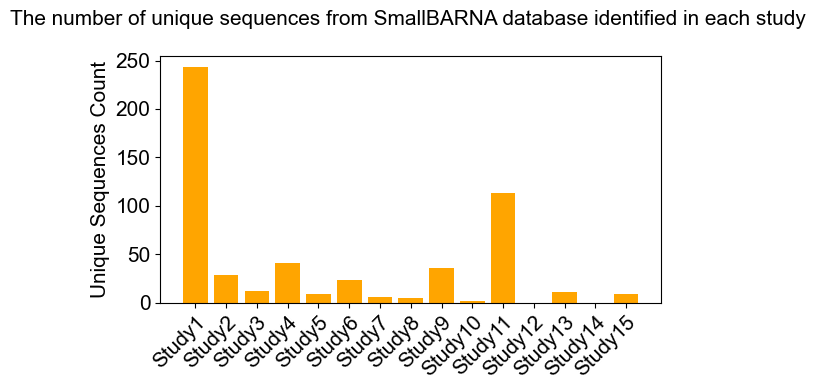

In [ ]:
#from matplotlib_venn import venn2
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import numpy as np
import pandas as pd
import os
#import seaborn as sns

fm.fontManager.addfont(str("arial.ttf"))

arial_font = fm.FontProperties(fname="arial.ttf", size=15)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=9)


labels = [f"Study{i}" for i in range(1, 16)]
values = [243, 29, 12, 41, 9, 23, 6, 5, 36, 2, 113, 0, 11, 0, 9]
plt.figure(figsize=(6, 4))
plt.bar(labels, values, color="orange")
#set y-axis limit
#plt.ylim(0, 746)

#labels and title with arial
#plt.xlabel("Studies", fontproperties=arial_font)

#Count of unique sequences reported in paper each study
plt.ylabel("Unique Sequences Count", fontproperties=arial_font)
plt.title("The number of unique sequences from SmallBARNA database identified in each study ", fontproperties=arial_font, pad=22)

#apply arial to ticks
plt.xticks(fontproperties=arial_font, rotation=45, ha="right", rotation_mode="anchor")
plt.yticks(fontproperties=arial_font)
plt.tight_layout()
#plt.show()
plt.savefig("fig1.pdf", format="pdf", bbox_inches="tight")

In [ ]:


def count_groups_per_fasta_name(fa_file, groups):
    """
    Read a .fa file, extract sequence names from '>' headers,
    and report how many dataset groups each name appears in.
    """
    #parse sequence names from fasta
    fa_names = []
    with open(fa_file, "r") as f:
        for line in f:
            line = line.strip()
            if line.startswith(">"):
                name = line[1:].split()[0]  #first word after '>'
                fa_names.append(name)
    print(len(fa_names))
    print(type(groups)) 
    #for each fasta name, find which groups contain it
    results = []
    for name in fa_names:
        matched_groups = []
        for group_key in sorted(groups):
            if name in groups[group_key]["names"]:
                matched_groups.append(group_key)
        results.append({
            "name": name,
            "group_count": len(matched_groups),
            "groups": matched_groups,
        })

    #print results
    print("=== Groups per FASTA entry ===")
    for r in results:
        print(f"{r['name']}: {r['group_count']} group(s) -> {', '.join(r['groups'])}")
    print(f"\nTotal FASTA entries: {len(results)}")
    group_counts = sorted((x["group_count"] for x in results), reverse=True)
    return results, group_counts



In [5]:
folder = os.path.dirname("smallbarna_blastn_results/")
groups = process_csv_groups(folder)
results, group_counts = count_groups_per_fasta_name("SmallBARNA.fa", groups)
print(group_counts)

=== dataset1 ===
Source files: map_genome_srna_compare_dataset1_SRR18745680_final_form/blast_score_filter.txt, map_genome_srna_compare_dataset1_SRR18745681_final_form/blast_score_filter.txt, map_genome_srna_compare_dataset1_SRR18745682_final_form/blast_score_filter.txt, map_genome_srna_compare_dataset1_SRR18745683_final_form/blast_score_filter.txt, map_genome_srna_compare_dataset1_SRR18745684_final_form/blast_score_filter.txt, map_genome_srna_compare_dataset1_SRR18745685_final_form/blast_score_filter.txt, map_genome_srna_compare_dataset1_SRR18745686_final_form/blast_score_filter.txt, map_genome_srna_compare_dataset1_SRR18745687_final_form/blast_score_filter.txt, map_genome_srna_compare_dataset1_SRR18745688_final_form/blast_score_filter.txt, map_genome_srna_compare_dataset1_SRR18745689_final_form/blast_score_filter.txt, map_genome_srna_compare_dataset1_SRR18745690_final_form/blast_score_filter.txt
Unique name count: 243
Unique names: ['sRNA-Aacti-52', 'sRNA-Apleu-10', 'sRNA-Apleu-3', 's

318
169
26
10
4
[ 9.00000000e+000  7.11190835e+000  4.00020659e+000  3.97381755e+000
  3.02240360e+000  2.99249057e+000  2.99995261e+000  3.00000133e+000
  2.99994811e+000  3.00643813e+000  3.04560257e+000  2.02877539e+000
  2.00037586e+000  1.99996012e+000  1.99999938e+000  2.00000006e+000
  2.00000000e+000  2.00000000e+000  2.00000000e+000  2.00000000e+000
  2.00000000e+000  2.00000000e+000  2.00000000e+000  2.00000000e+000
  2.00000000e+000  2.00000000e+000  2.00000000e+000  2.00000000e+000
  2.00000000e+000  2.00000000e+000  2.00000000e+000  2.00000000e+000
  2.00000000e+000  2.00000000e+000  2.00000000e+000  2.00000000e+000
  2.00000000e+000  2.00000000e+000  2.00000000e+000  2.00000000e+000
  2.00000000e+000  2.00000000e+000  2.00000000e+000  2.00000000e+000
  2.00000000e+000  2.00000000e+000  2.00000000e+000  2.00000000e+000
  2.00000000e+000  2.00000000e+000  2.00000000e+000  2.00000000e+000
  2.00000000e+000  2.00000000e+000  2.00000000e+000  2.00000000e+000
  2.00000000e+000 

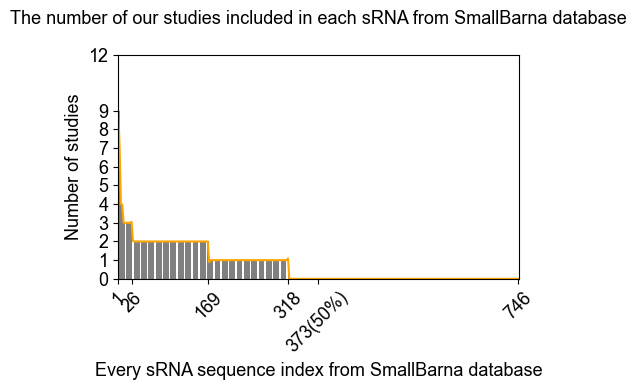

In [ ]:
#from matplotlib_venn import venn2
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import numpy as np
import pandas as pd
import os
from scipy.interpolate import make_interp_spline
#import seaborn as sns

fm.fontManager.addfont(str("arial.ttf"))

arial_font = fm.FontProperties(fname="arial.ttf", size=13)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=9)


labels = [f"{i}" for i in range(1, 747)]

values = group_counts
#x = list(range(len(values)))
x = np.arange(len(labels))
count = sum(1 for x in values if x > 0)
print(count)
count = sum(1 for x in values if x > 1)
print(count)
count = sum(1 for x in values if x > 2)
print(count)
count = sum(1 for x in values if x > 3)
print(count)
count = sum(1 for x in values if x > 4)
print(count)
plt.figure(figsize=(5, 4))
plt.bar(labels, values, color="gray")
#plt.plot(labels, values, marker="o",size="1")

x_smooth = np.linspace(x.min(), x.max(), 300)
y_smooth = make_interp_spline(x, values, k=3)(x_smooth)
print(y_smooth)
plt.plot(x_smooth, y_smooth, color="orange")

#show_idx = [0, 317, "50%", 746] #positions you want to show
#plt.xticks([x[i] for i in show_idx], [labels[i] for i in show_idx])
#set y-axis limit
plt.ylim(0, 12)
plt.xlim(1,746)

plt.xlabel("Every sRNA sequence index from SmallBarna database",fontproperties=arial_font)
plt.ylabel("Number of studies",fontproperties=arial_font)
plt.title(f"The number of our studies included in each sRNA from SmallBarna database",fontproperties=arial_font, pad=22)
#apply Arial to ticks
#plt.xticks()
plt.xticks([0, 25, 168, 317, 372, 745], ["1","26","169", "318", "373(50%)", "746"],fontproperties=arial_font, rotation=45)
plt.yticks([0,1,2,3,4,5,6,7,8,9,12],["0","1","2","3","4","5","6","7","8","9","12"],fontproperties=arial_font)
plt.tight_layout()
#plt.show()
plt.savefig("fig2.pdf", format="pdf", bbox_inches="tight")